# Ollama VLM Benchmark

We test how well an open-weights vision-language model (VLM) running **locally through Ollama** can classify our brain MRI scans into the four classes (`glioma`, `meningioma`, `notumor`, `pituitary`) **without any training**.

A VLM is a language model with an image front end. A vision encoder turns the picture into a grid of embeddings, a small projector maps them into the language model's token space, and the language model then reads those image tokens next to our text prompt and writes an answer. We never update any weights here, we only change what we show the model.

We try two setups:

1. **Zero-shot**: the model only gets the image and a description of the task.
2. **Few-shot**: the model also gets a few labelled example images taken from our **training set**, so it can see what each class looks like in this dataset before it classifies a test image.

We use the same splits and metrics as the other notebooks, so the results can be compared directly with `Naive_Benchmark.ipynb` (macro F1 ≈ 0.25) and `Decision_Tree_Baseline.ipynb`. Because the model runs on our own GPU, there is no API key, no rate limit and no cost per image.

## Setup

1. Install [Ollama](https://ollama.com) and make sure it is running. The desktop app starts the server in the background, otherwise run `ollama serve` in a terminal.
2. Download a vision model once (about 3 GB): `ollama pull qwen2.5vl:3b`. If your GPU has 8 GB of memory or more, you can also try the larger `qwen2.5vl:7b` (about 6 GB). Run `ollama list` to see which models you have.
3. Install the Python packages. `ollama` (the Python client) is now listed in `requirements.txt`, so re-run this if your virtual environment is older:

```bash
pip install -r requirements.txt
```

No API key is needed. If Ollama runs on a different machine, set the `OLLAMA_HOST` environment variable (for example `http://192.168.1.20:11434`) before starting Jupyter.

In [ ]:
import os
import re
import csv
import enum
import time
from pathlib import Path

import httpx
import ollama
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay

## Configuration

All the settings for the experiment are in one place:

- `MODEL`: which Ollama model to use. It must be a **vision** model that you pulled with `ollama pull` (text-only models such as `qwen3:8b` cannot see images). The default, `qwen2.5vl:3b`, is small enough for a laptop GPU with about 4 GB of memory. A 7B model such as `qwen2.5vl:7b` needs very roughly 6-8 GB, and if it does not fit, Ollama runs part of it on the CPU, which is much slower. Compare models by changing this one line and re-running.
- `SAMPLE_PER_CLASS`: how many test images per class to classify. Start with a stratified sample (50 per class = 200 images) to check the setup and estimate the run time, then set it to `None` for the full test set. Results are cached per image, so the full run only classifies the images that the sample did not already cover.
- `FEW_SHOT_PER_CLASS`: how many labelled training images per class to show the model in the few-shot setup.
- `SEED`: makes the sampling reproducible and also seeds the model's own sampling.
- `NUM_CTX`: the context window in tokens, i.e. the longest prompt the model accepts. With `qwen2.5vl:3b`, Ollama turns **every image into about 1,050 tokens regardless of its size**, so the few-shot prompt (8 examples + the test image) is about 9,600 tokens. If the prompt is longer than `NUM_CTX`, Ollama refuses the request with `exceeds the available context size`. Rule of thumb: `NUM_CTX` ≥ 1,100 × (4 × `FEW_SHOT_PER_CLASS` + 1) + 500, so 12288 for 2 examples per class, 8192 for 1.

**Why few-shot is not 9× slower:** the 8 example images are identical in every request, so Ollama reuses the work it already did on them and only processes the new test image. On a 4 GB laptop GPU we measured about 2.7 s per image zero-shot and 3.5 s few-shot. This only works because the notebook runs all zero-shot images first and then all few-shot images.

**Checking that the model fits on your GPU:** after the sanity check below has run, type `ollama ps` in a terminal. `100% GPU` in the PROCESSOR column means everything fits. Something like `55%/45% CPU/GPU` means part of the model runs on the CPU. On a 4 GB GPU that happens even with the 3B model, but it still runs at the speeds above. A larger `NUM_CTX` uses a bit more memory.

In [ ]:
MODEL = "qwen2.5vl:3b"
SAMPLE_PER_CLASS = 50       # None = full test set
FEW_SHOT_PER_CLASS = 2
SEED = 0
NUM_CTX = 12288             # few-shot prompt is ~9,600 tokens (each image ~1,050), see above

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
DATA_DIR = Path("../data/")
RESULTS_DIR = DATA_DIR / "vlm_results"     # kept apart from data/processed, which holds the classical models' .npz arrays
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Talks to http://localhost:11434 unless the OLLAMA_HOST environment variable says otherwise.
# The long timeout is for the first request, which has to load the model into GPU memory.
client = ollama.Client(timeout=600)

## Check that Ollama is running

Before doing anything else, we make sure the server answers and that the model has been pulled, so a missing model gives one clear message instead of hundreds of failed calls.

In [17]:
def check_ollama():
    try:
        installed = [m.model for m in client.list().models]
    except Exception as e:
        raise RuntimeError(
            "Cannot reach the Ollama server. Start the Ollama app (or run `ollama serve`) and try again."
        ) from e
    if MODEL not in installed and f"{MODEL}:latest" not in installed:
        raise RuntimeError(f"Model '{MODEL}' is not installed. Run `ollama pull {MODEL}`. Installed models: {installed}")
    print(f"Ollama is running and '{MODEL}' is installed.")

check_ollama()

Ollama is running and 'qwen2.5vl:3b' is installed.


## Load data

We use the same `train.csv` / `test.csv` splits produced by `Preprocessing_Data.ipynb`. The model receives the **original JPEG files**, not the preprocessed `.npz` arrays, since that is the input format a VLM expects. Ollama then resizes each image to the model's own input size, so the VLM sees a different (colour, higher-resolution) version of each scan than the classical models, which see 224x224 or 64x64 grayscale arrays. This is worth stating when we compare them.

The CSV paths were saved with Windows backslashes, so we convert them to forward slashes so they also work on macOS/Linux.

In [18]:
def load_csv(name):
    df = pd.read_csv(DATA_DIR / f"{name}.csv")
    df["Path"] = df["Path"].str.replace("\\", "/", regex=False)
    return df

train_df = load_csv("train")
test_df = load_csv("test")

if SAMPLE_PER_CLASS is not None:
    test_df = test_df.groupby("Labels").sample(n=SAMPLE_PER_CLASS, random_state=SEED).reset_index(drop=True)

print(f"train: {len(train_df)} images, test (to classify): {len(test_df)} images")
print(test_df["Labels"].value_counts())

train: 4728 images, test (to classify): 200 images
Labels
glioma        50
meningioma    50
notumor       50
pituitary     50
Name: count, dtype: int64


## Structured output

Free text answers like *"This looks like a pituitary adenoma"* would need messy string parsing. Instead we pass a **JSON schema** to Ollama: it constrains the model's output so the reply is always JSON whose `label` field is one of our four class names. We then parse it into a Python object.

One consequence worth remembering: the model is forced to pick one of the four classes, it cannot answer "unsure".

In [19]:
class TumourClass(str, enum.Enum):
    glioma = "glioma"
    meningioma = "meningioma"
    notumor = "notumor"
    pituitary = "pituitary"

class Prediction(BaseModel):
    label: TumourClass

RESPONSE_SCHEMA = Prediction.model_json_schema()

## Prompt

The prompt explains the task and describes each class in plain radiological terms, so the model knows exactly what the label names mean (e.g. that `notumor` is a healthy scan). It is sent as the system message. Keep it fixed when comparing different models, so differences in the results come from the model and not from the wording.

In [20]:
PROMPT = '''You are an expert neuroradiologist. You will be shown a brain MRI slice.
Classify it into exactly one of these classes:

- glioma: an infiltrative tumour arising from glial cells within the brain tissue, often with irregular borders and surrounding oedema.
- meningioma: a well-defined, extra-axial tumour arising from the meninges, usually attached to the skull or dura.
- pituitary: a tumour in the sella turcica region at the base of the brain, below the optic chiasm.
- notumor: a healthy brain with no visible tumour.

Answer with the single most likely class.'''

## Few-shot examples from the training set

For the few-shot setup we randomly pick `FEW_SHOT_PER_CLASS` labelled images per class from the **training set** (never the test set, so there is no leakage). With the same `SEED`, every model and every teammate gets the same example images.

Ollama is a chat API, so each example becomes a short conversation turn: a `user` message with the example image, then an `assistant` message with the correct answer in the same JSON format we ask for. That is the format chat models were trained on, and it also works for models that only accept one image per message. The examples are **shuffled**, otherwise the last example would always be the same class and could nudge the model towards it.

They are sent with every request, before the image to classify.

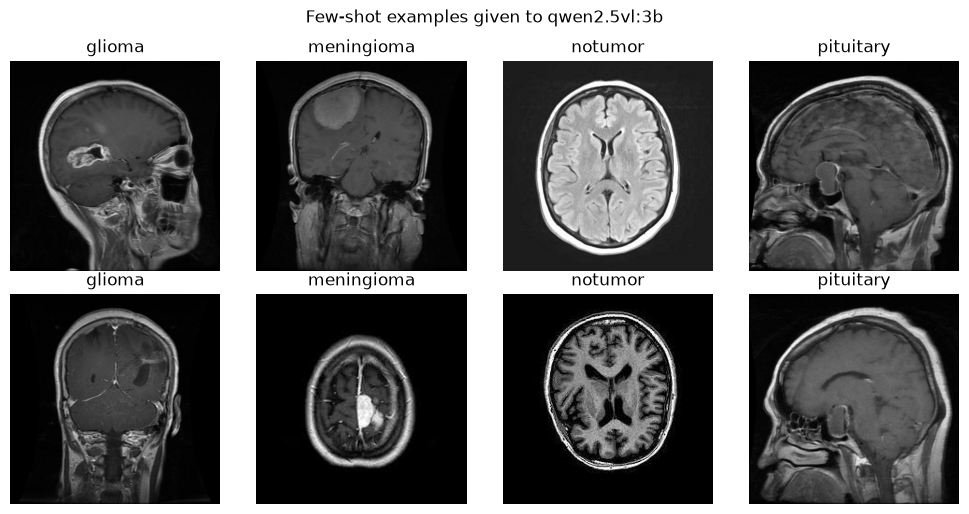

In [21]:
few_shot_df = (
    train_df.groupby("Labels").sample(n=FEW_SHOT_PER_CLASS, random_state=SEED)
    .sample(frac=1, random_state=SEED)     # shuffle the order of the examples
)

def image_bytes(path):
    return Path(path).read_bytes()

def label_json(label):
    return Prediction(label=label).model_dump_json()     # '{"label":"glioma"}'

# Build the example turns once and reuse them for every request
FEW_SHOT_MESSAGES = []
for _, row in few_shot_df.iterrows():
    FEW_SHOT_MESSAGES += [
        {"role": "user", "content": "Classify this scan.", "images": [image_bytes(row["Path"])]},
        {"role": "assistant", "content": label_json(row["Labels"])},
    ]

fig, axes = plt.subplots(FEW_SHOT_PER_CLASS, len(CLASSES), figsize=(10, 2.6 * FEW_SHOT_PER_CLASS), squeeze=False)
for col, (label, group) in enumerate(few_shot_df.groupby("Labels")):
    for row_i, path in enumerate(group["Path"]):
        axes[row_i, col].imshow(plt.imread(path), cmap="gray")
        axes[row_i, col].set_title(label)
        axes[row_i, col].axis("off")
plt.suptitle(f"Few-shot examples given to {MODEL}")
plt.tight_layout()
plt.show()

## Classifying one image

`chat_once` sends one image (plus the few-shot examples, if requested) to the model with `temperature=0` so the answers are as deterministic as possible. `classify_image` wraps it and returns the predicted label.

There is no rate limit with a local model, but calls can still fail, for example a timeout while the model loads or an out-of-memory error from the server. In those cases we wait and retry with exponential backoff (2 s, 4 s). If it still fails after `max_retries`, we return `None` and the image is counted as an error rather than crashing the whole run.

In [22]:
def build_messages(path, few_shot=False):
    messages = [{"role": "system", "content": PROMPT}]
    if few_shot:
        messages += FEW_SHOT_MESSAGES
    messages.append({"role": "user", "content": "Classify this scan.", "images": [image_bytes(path)]})
    return messages

def chat_once(path, few_shot=False):
    return client.chat(
        model=MODEL,
        messages=build_messages(path, few_shot),
        format=RESPONSE_SCHEMA,
        options={"temperature": 0, "seed": SEED, "num_ctx": NUM_CTX},
    )

def classify_image(path, few_shot=False, max_retries=3):
    for attempt in range(max_retries):
        try:
            response = chat_once(path, few_shot)
            return Prediction.model_validate_json(response.message.content).label.value
        except ollama.ResponseError as e:
            error, retryable = e, e.status_code >= 500
        except (ConnectionError, httpx.TransportError) as e:
            error, retryable = e, True
        except ValueError as e:  # reply could not be parsed into a label
            print(f"Unparseable reply for {path}: {e}")
            return None

        if retryable and attempt < max_retries - 1:
            time.sleep(2 ** (attempt + 1))
        else:
            print(f"Failed on {path}: {error}")
            return None

### Sanity check

Before looping over hundreds of images, we test the function on a single test image to make sure the server, model name and schema all work. It also prints how many prompt tokens each setup uses and how long one call takes, which is useful for two things:

- **Run time**: multiply the seconds per image by the number of images to estimate a full run. The very first call is slower because it loads the model into GPU memory, and the first few-shot call is slower because the example images are processed for the first time.
- **Context window**: the few-shot prompt token count must be below `NUM_CTX`. If this cell fails with `exceeds the available context size`, raise `NUM_CTX` (or lower `FEW_SHOT_PER_CLASS`) in the configuration cell and re-run from there.

In [23]:
sample = test_df.iloc[0]
print("true label:", sample["Labels"])

for few_shot in (False, True):
    r = chat_once(sample["Path"], few_shot=few_shot)
    label = Prediction.model_validate_json(r.message.content).label.value
    secs = (r.total_duration or 0) / 1e9
    name = "few-shot " if few_shot else "zero-shot"
    print(f"{name}: {label:<10} prompt tokens = {r.prompt_eval_count}, time = {secs:.1f}s")

print(f"context window (NUM_CTX) = {NUM_CTX} tokens")

true label: glioma
zero-shot: glioma     prompt tokens = 1193, time = 3.4s
few-shot : notumor    prompt tokens = 9640, time = 26.7s
context window (NUM_CTX) = 12288 tokens


## Classifying the test set

`classify_dataset` goes through every image in a dataframe and records the model's prediction.

Because a full run takes a while, each successful prediction is **appended to a CSV after every image** (in `data/vlm_results/`, which is git-ignored and only holds this notebook's results). If the run is interrupted (closed laptop, Ollama restarted), simply re-run the cell: images that already have a prediction are skipped and it picks up where it left off. Images where the call failed are not saved, so a re-run retries them.

The file name contains the model name, so each model gets its own results. The cache is **not** keyed on the prompt, `NUM_CTX`, `FEW_SHOT_PER_CLASS` or `SEED`: if you change one of those, delete the CSV to start from scratch.

In [24]:
def cache_file(mode):
    safe_model = re.sub(r"[^A-Za-z0-9._-]", "_", MODEL)   # ':' in 'qwen2.5vl:3b' is not allowed in Windows file names
    return RESULTS_DIR / f"ollama_{safe_model}_{mode}.csv"

def classify_dataset(df, few_shot=False):
    mode = "few_shot" if few_shot else "zero_shot"
    path = cache_file(mode)

    done = {}
    if path.exists() and path.stat().st_size > 0:
        cached = pd.read_csv(path)
        done = dict(zip(cached["Path"], cached["Prediction"]))
    write_header = not path.exists() or path.stat().st_size == 0

    rows = []
    start = time.time()
    with open(path, "a", newline="") as f:
        writer = csv.writer(f)
        if write_header:
            writer.writerow(["Path", "Prediction"])
            f.flush()

        for i, row in enumerate(df.itertuples(), start=1):
            pred = done.get(row.Path)
            if pred is None:
                pred = classify_image(row.Path, few_shot=few_shot)
                if pred is not None:          # failures are not cached, so a re-run tries them again
                    writer.writerow([row.Path, pred])
                    f.flush()
                    done[row.Path] = pred
            rows.append({"Path": row.Path, "Labels": row.Labels, "Prediction": pred})

            if i % 25 == 0 or i == len(df):
                print(f"[{mode}] {i}/{len(df)} images ({time.time() - start:.0f}s)")

    return pd.DataFrame(rows)

### Zero-shot run

In [25]:
zero_shot_results = classify_dataset(test_df, few_shot=False)
zero_shot_results.head()

[zero_shot] 25/200 images (71s)
[zero_shot] 50/200 images (144s)
[zero_shot] 75/200 images (217s)
[zero_shot] 100/200 images (289s)
[zero_shot] 125/200 images (374s)
[zero_shot] 150/200 images (453s)
[zero_shot] 175/200 images (523s)
[zero_shot] 200/200 images (595s)


,Path,Labels,Prediction
0,../data/Testing/glioma/Te-gl_341.jpg,glioma,glioma
1,../data/Testing/glioma/Te-gl_399.jpg,glioma,glioma
2,../data/Testing/glioma/Te-gl_230.jpg,glioma,glioma
3,../data/Testing/glioma/Te-gl_146.jpg,glioma,glioma
4,../data/Testing/glioma/Te-gl_295.jpg,glioma,glioma


### Few-shot run

In [ ]:
few_shot_results = classify_dataset(test_df, few_shot=True)
few_shot_results.head()

[few_shot] 25/200 images (130s)
[few_shot] 50/200 images (236s)
[few_shot] 75/200 images (340s)
[few_shot] 100/200 images (444s)
[few_shot] 125/200 images (573s)
[few_shot] 150/200 images (685s)


## Evaluation

We use the same metrics as the other notebooks: accuracy, macro F1 and a per-class report. Any image where the call failed (`None`) is counted as **wrong**, so failures cannot inflate the score.

The confusion matrix shows *which* classes the model mixes up, which is more informative than the overall score alone. We also count the most serious error, the same one `Decision_Tree_Baseline.ipynb` highlights: a scan with a tumour that the model calls `notumor`.

In [ ]:
def evaluate(results, title):
    n_failed = int(results["Prediction"].isna().sum())
    y_true = results["Labels"]
    y_pred = results["Prediction"].fillna("failed")

    has_tumour = y_true != "notumor"
    missed = int((has_tumour & (y_pred == "notumor")).sum())

    print(f"===== {title} =====")
    print(f"failed calls: {n_failed}/{len(results)}")
    print(f"tumour scans predicted as 'notumor': {missed}/{int(has_tumour.sum())}")
    print(classification_report(y_true, y_pred, labels=CLASSES, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=CLASSES, cmap="Blues")
    plt.title(f"{title} ({MODEL})")
    plt.show()

    return {
        "setup": title,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0),
        "missed_tumours": missed,
        "failed": n_failed,
    }

summary = [
    evaluate(zero_shot_results, "Zero-shot"),
    evaluate(few_shot_results, "Few-shot"),
]

## Summary

Side-by-side comparison of both setups against the naive (stratified random) baseline from `Naive_Benchmark.ipynb`, which scored ≈ 0.25 macro F1.

In [ ]:
summary_df = pd.DataFrame(summary + [{"setup": "Naive baseline", "accuracy": 0.25, "macro_f1": 0.25, "missed_tumours": None, "failed": 0}])
print(f"Model: {MODEL}, test images: {len(test_df)}")
summary_df.round(3)

## Conclusions

*To fill in after running:*

- How does the zero-shot model compare with the naive baseline and the decision tree?
- Does showing a few labelled training examples (few-shot) help, and for which classes?
- Which classes does the model confuse most often (see the confusion matrices), and how many tumour scans does it call `notumor`?
- If you tried more than one `MODEL`, how do they compare?
- Caveats: results are on a stratified sample of `SAMPLE_PER_CLASS` images per class unless run on the full test set, the VLM sees the original JPEGs while the classical models see downsampled grayscale arrays, and general-purpose VLMs are not trained or validated for medical diagnosis.